# Sprint 6 (supplement) — How the prior width $T_a$ moves the threshold

**Question.** How does the threshold depend on how uncertain the delay is *before* we look at the data? Professors
often ask: "what if the delay were known more precisely, or less?" The brief also asks for "similar observations of
the ZZB curve with others".

**Why it matters.** The threshold is caused by *wrong peaks inside the search window*. A wider window (larger $T_a$)
contains more places where noise can create a winning peak, so the threshold should move to *higher* SNR. With a
window about one correlation main lobe wide ($T_a=1$), there is no distant peak to jump to, so the threshold should be
masked. This was seen in an untrusted October smoke test (1000 trials, older code); here it is measured properly.

**Set-up.** Pilot 2026, $T_a\in\{1,4,16\}$ chips, MLE and MMSE, 10,000 trials per point, 1-dB grid, bootstrap CIs
(200 resamples). *Runtime ≈ 5–10 min.*

**What theory predicts (Mallat et al. 2014, Part 2):** the *asymptotic* threshold depends only on the pulse shape,
but the *a-priori* threshold depends on the prior width — so we expect the threshold to grow with $T_a$.

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

In [2]:
def crossing(x, y, level):
    y = np.maximum(y, 1e-12)
    for i in range(len(x) - 1, 0, -1):
        if y[i] <= level < y[i - 1]:
            f = (np.log(level) - np.log(y[i])) / (np.log(y[i - 1]) - np.log(y[i]))
            return x[i] + f * (x[i - 1] - x[i])
    return np.nan

def thr(snr, err, cr):
    return crossing(snr, np.mean(err ** 2, 1) / cr, 2.0), crossing(snr, np.mean(np.abs(err) > 0.5, 1), 0.01)

def boot(snr, err, cr, n=200, seed=0):
    g = np.random.default_rng(seed)
    b = np.array([thr(snr, np.take_along_axis(err, g.integers(0, err.shape[1], err.shape), 1), cr) for _ in range(n)])
    return thr(snr, err, cr), np.nanpercentile(b, [2.5, 97.5], axis=0)

grids = {1.0: np.arange(-6.0, 14.01, 1.0), 4.0: np.arange(2.0, 16.01, 1.0), 16.0: np.arange(6.0, 18.01, 1.0)}
N = 10000
out = {}
for ta, snr in grids.items():
    cfg = Config(prior_width=ta)
    sc = BatchScenario(cfg, np.random.default_rng(cfg.seed))      # same pilot (seed 2026) for every Ta
    mle, rng = BatchMLE(sc), np.random.default_rng(int(ta * 10))
    en0 = 10 ** (snr / 10)
    e_ml, e_mm = np.empty((snr.size, N)), np.empty((snr.size, N))
    for i, e in enumerate(en0):
        tau = sc.draw_delays(N, rng)
        for c in range(0, N, 1000):
            sl = slice(c, c + 1000)
            ml, mm = mle.estimate_both(sc.observe(tau[sl], e, rng), sc.sigma2(e))
            e_ml[i, sl], e_mm[i, sl] = ml - tau[sl], mm - tau[sl]
    cr = crlb(sc, en0)
    xf = np.linspace(snr[0], snr[-1], 400)
    zf, cf = zzb(sc, 10 ** (xf / 10)), crlb(sc, 10 ** (xf / 10))
    out[ta] = dict(snr=snr, cr=cr, xf=xf, zf=zf, cf=cf, mse_ml=np.mean(e_ml ** 2, 1), mse_mm=np.mean(e_mm ** 2, 1),
                   b_ml=boot(snr, e_ml, cr, seed=1), b_mm=boot(snr, e_mm, cr, seed=2),
                   zzb_thr=crossing(xf, zf / cf, 2.0))
    o = out[ta]
    print(f"Ta = {ta:4.1f}: ZZB {o['zzb_thr']:6.2f} | MMSE {o['b_mm'][0][0]:6.2f} {np.round(o['b_mm'][1][:, 0], 2)} | "
          f"MLE {o['b_ml'][0][0]:6.2f} {np.round(o['b_ml'][1][:, 0], 2)}   (MSE criterion, dB)", flush=True)
    print(f"           gross criterion: MMSE {o['b_mm'][0][1]:6.2f}  MLE {o['b_ml'][0][1]:6.2f};  "
          f"MSE at lowest SNR: MLE {o['mse_ml'][0]:.3f}, MMSE {o['mse_mm'][0]:.3f}, Ta^2/12 = {ta ** 2 / 12:.3f}")

C:\Users\Nilavra Ghosh\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Ta =  1.0: ZZB    nan | MMSE    nan [nan nan] | MLE    nan [nan nan]   (MSE criterion, dB)


           gross criterion: MMSE   5.98  MLE   8.20;  MSE at lowest SNR: MLE 0.193, MMSE 0.077, Ta^2/12 = 0.083


Ta =  4.0: ZZB   5.95 | MMSE   8.84 [8.58 9.14] | MLE   9.34 [ 8.81 10.08]   (MSE criterion, dB)


           gross criterion: MMSE   9.65  MLE   9.46;  MSE at lowest SNR: MLE 1.047, MMSE 0.637, Ta^2/12 = 1.333


Ta = 16.0: ZZB  11.56 | MMSE  12.99 [11.97 13.37] | MLE  13.01 [11.95 13.41]   (MSE criterion, dB)


           gross criterion: MMSE  11.42  MLE  10.73;  MSE at lowest SNR: MLE 9.843, MMSE 6.845, Ta^2/12 = 21.333


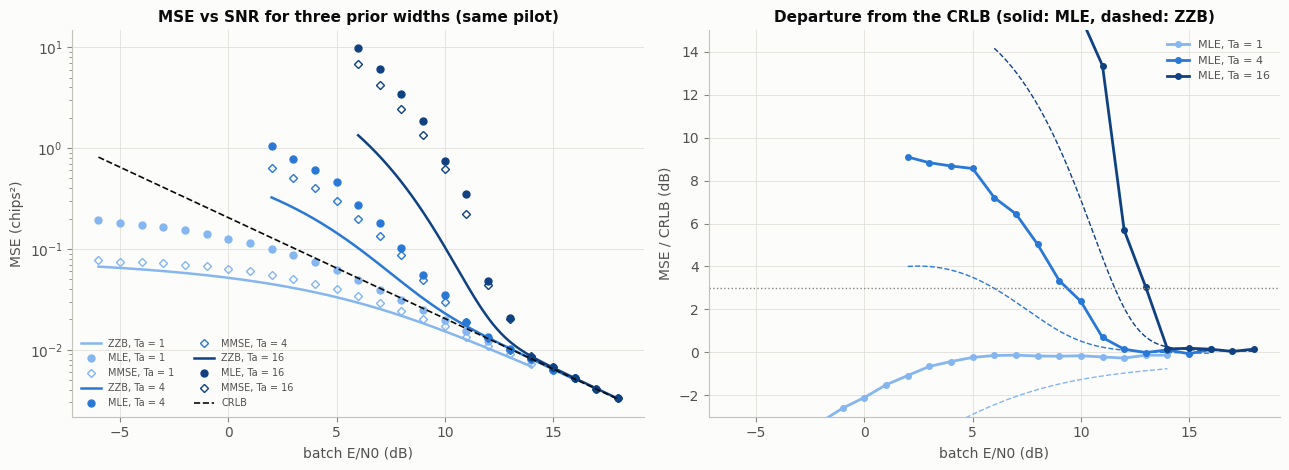

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ramp = ["#86b6ef", "#2a78d6", "#104281"]
o4 = out[4.0]
for color, ta in zip(ramp, out):
    o = out[ta]
    ax[0].semilogy(o["xf"], o["zf"], color=color, lw=1.8, label=f"ZZB, Ta = {ta:g}")
    ax[0].semilogy(o["snr"], o["mse_ml"], "o", color=color, ms=5, label=f"MLE, Ta = {ta:g}")
    ax[0].semilogy(o["snr"], o["mse_mm"], "D", color=color, ms=4, mfc="none", label=f"MMSE, Ta = {ta:g}")
    ax[1].plot(o["snr"], 10 * np.log10(o["mse_ml"] / o["cr"]), "o-", color=color, ms=4, label=f"MLE, Ta = {ta:g}")
    ax[1].plot(o["xf"], 10 * np.log10(o["zf"] / o["cf"]), color=color, lw=1, ls="--")
allx = np.linspace(-6, 18, 300)
sc_ref = BatchScenario(Config(), np.random.default_rng(2026))     # same pilot; the CRLB does not depend on Ta
ax[0].semilogy(allx, crlb(sc_ref, 10 ** (allx / 10)), color=COLORS["crlb"], ls="--", lw=1.2, label="CRLB")
ax[0].set_xlabel("batch E/N0 (dB)"); ax[0].set_ylabel("MSE (chips²)")
ax[0].set_title("MSE vs SNR for three prior widths (same pilot)"); ax[0].legend(fontsize=7, ncol=2, loc="lower left")
ax[1].axhline(10 * np.log10(2), color=MUTED, ls=":", lw=1)
ax[1].set_ylim(-3, 15); ax[1].set_xlabel("batch E/N0 (dB)"); ax[1].set_ylabel("MSE / CRLB (dB)")
ax[1].set_title("Departure from the CRLB (solid: MLE, dashed: ZZB)"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s6_prior_width.png")

## Results and what they mean

| Prior width $T_a$ | ZZB threshold | MMSE threshold (95 % CI) | MLE threshold (95 % CI) | MLE − ZZB |
|---|---|---|---|---|
| 1 chip | none | none (masked) | none (masked) | — |
| 4 chips | 5.95 dB | 8.84 [8.58, 9.14] dB | 9.34 [8.81, 10.08] dB | 3.4 dB |
| 16 chips | 11.56 dB | 12.99 [11.97, 13.37] dB | 13.01 [11.95, 13.41] dB | 1.5 dB |

*(MSE criterion; 10,000 trials per point. The $T_a=4$ values agree, within their intervals, with the 20,000-trial
values of notebook 06: MLE 9.52, MMSE 8.54 dB.)*

**1. A wider prior pushes the threshold to higher SNR**, by about 3.7 dB from $T_a=4$ to $T_a=16$ for the MLE. A wider
window holds more places where noise can create a winning peak, so a stronger signal is needed before the true peak
reliably wins. This is the a-priori-threshold dependence on the prior domain described by Mallat et al. (2014).

**2. With $T_a=1$ chip the threshold is masked, not absent.** The window is about one correlation main lobe wide, so
there is no distant peak to jump to; every error is clipped by the window. The MLE's MSE never exceeds 2×CRLB
(right plot: it stays at or below the CRLB). At low SNR the CRLB rises above the prior variance (0.083 chips²) while the ZZB levels off at it.
Gross errors (> 0.5 chip) still occur near the window edges: by the gross-error criterion the MLE reaches 1 % at
8.2 dB and the MMSE at 6.0 dB.

**3. The ZZB becomes relatively tighter as the prior widens:** MLE − ZZB shrinks from 3.4 dB ($T_a=4$) to 1.5 dB
($T_a=16$), and the MMSE and MLE thresholds coincide at $T_a=16$. One plausible reading: with many competing peaks,
the threshold is set by the *far* errors that the ZZB's pairwise construction captures well, while at $T_a=4$ it is
set by near-main-lobe confusions where the pairwise bound is loose. This is an interpretation, not something we have
tested.

**4. Very low SNR.** The MMSE's MSE approaches the prior variance from below; the MLE's exceeds it at $T_a=1$
(0.193 vs 0.083 at −6 dB) because its estimates pile up at the window edges — the same effect as at $T_a=4$.
